In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import pearsonr

#load the csv file
df = pd.read_csv("dry straight hair data/Extension_Dry_2mmmin_S.csv")
print(df)

       Record  Strain (%)  Stress (MPa)
0           1         0.0           0.1
1           1         0.0          -0.1
2           1         0.0           0.0
3           1         0.0           0.1
4           1         0.0           0.0
...       ...         ...           ...
20288      25         4.0           3.2
20289      25         4.0           3.3
20290      25         4.0           3.2
20291      25         4.0           3.7
20292      25         4.0           4.1

[20293 rows x 3 columns]


In [8]:
#Convert columns to numbers
df["Strain (%)"] = pd.to_numeric(df["Strain (%)"], errors='coerce')
df["Stress (MPa)"] = pd.to_numeric(df["Stress (MPa)"], errors='coerce')
df = df.dropna(subset=["Strain (%)", "Stress (MPa)"])  # Drop rows with NaN values in these columns

#Sort by strain
df = df.sort_values("Strain (%)")

#Check the data
print(df.head())
print(df.info())

    Record  Strain (%)  Stress (MPa)
0        1         0.0           0.1
20       1         0.0           0.3
19       1         0.0           0.1
18       1         0.0           0.1
17       1         0.0           0.1
<class 'pandas.core.frame.DataFrame'>
Index: 20293 entries, 0 to 14608
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Record        20293 non-null  int64  
 1   Strain (%)    20293 non-null  float64
 2   Stress (MPa)  20293 non-null  float64
dtypes: float64(2), int64(1)
memory usage: 634.2 KB
None


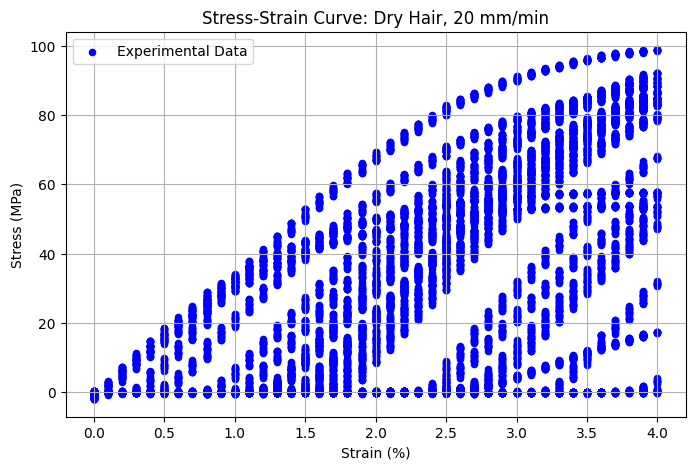

In [9]:
plt.figure(figsize=(8, 5)) #Raw stress-strain data
plt.scatter(df["Strain (%)"], df["Stress (MPa)"], s=20, label = "Experimental Data", color='blue')

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Stress-Strain Curve: Dry Hair, 20 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
mean_df = (df.groupby("Strain (%)")["Stress (MPa)"].agg(['mean', 'std']).reset_index())
print(mean_df)

    Strain (%)       mean        std
0          0.0  -0.116800   0.350542
1          0.1   0.115254   0.550406
2          0.2   0.431858   1.529547
3          0.3   0.765675   2.520360
4          0.4   1.225280   3.556654
5          0.5   1.608864   4.508679
6          0.6   2.107919   5.529312
7          0.7   2.858209   6.933278
8          0.8   3.613810   8.412869
9          0.9   4.017460   9.371288
10         1.0   4.918143  10.755273
11         1.1   6.059193  12.187243
12         1.2   6.062471  12.541429
13         1.3   7.569507  14.091612
14         1.4   8.824622  15.068180
15         1.5  10.387555  16.240812
16         1.6  11.872889  17.010702
17         1.7  13.814516  17.820386
18         1.8  15.816847  19.108032
19         1.9  17.512357  19.425618
20         2.0  20.320136  20.833202
21         2.1  22.272331  21.945615
22         2.2  24.309607  22.947064
23         2.3  26.711702  24.290469
24         2.4  28.072374  25.268133
25         2.5  31.049421  26.422272
2